# Predicting dropout from talking therapy

Which patients are more likely to drop out, using only what a service would
know by the third session?

The data comes from `analytics.patient_model_table` in BigQuery (built by the
dbt project in this repo). It's synthetic. See the README for how it was
generated. Effects on outcomes follow Kanso et al. (2026), and direct effects
on dropout follow Burke et al. (2025). So the point here is the method, and
what a model like this can and can't pick up, not new findings about real
patients.

Some people who drop out have already recovered and simply stopped coming. So
I look at two targets:

1. **Any dropout**: what services actually record.
2. **Dropout without reliable improvement**: people who left and hadn't
   improved, which is the group a service would most want to reach.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from google.cloud import bigquery
from sklearn.model_selection import train_test_split, cross_val_predict, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, roc_curve
import warnings
warnings.filterwarnings("ignore", message="BigQuery Storage module not found")
warnings.filterwarnings("ignore", category=FutureWarning)

BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10, "axes.edgecolor": GRID,
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.axisbelow": True, "axes.titlecolor": INK, "axes.titleweight": "bold",
    "axes.titlelocation": "left",
})
pd.set_option("display.precision", 3)

## Load the data

In [2]:
client = bigquery.Client(project="therapy-outcomes")
df = client.query("select * from analytics.patient_model_table").to_dataframe()

df["left_unimproved"] = df["is_dropped_out"] & ~df["has_reliable_improvement"]
df["is_ethnic_minority"] = df["ethnicity"] != "White"
df["is_25_to_35"] = df["age"].between(25, 35)
df["is_most_deprived"] = df["imd_decile"] <= 3
print(f"{len(df):,} patients who started treatment")
df.head()

3,980 patients who started treatment


,patient_id,age,is_under_25,is_female,ethnicity,religion,is_muslim,has_limited_english,imd_decile,is_unemployed,...,early_sessions_attended,is_early_engaged,early_phq9_change,is_dropped_out,is_recovered,has_reliable_improvement,left_unimproved,is_ethnic_minority,is_25_to_35,is_most_deprived
0,1729,35,False,False,White,Atheist/Agnostic,False,False,8,False,...,3,True,-2,False,True,True,False,False,True,False
1,4935,29,False,True,Asian,Muslim,True,False,4,False,...,2,True,-3,False,True,True,False,True,True,False
2,3717,43,False,False,White,Christian,False,False,2,False,...,3,True,-1,False,True,True,False,False,False,True
3,2580,50,False,True,White,Atheist/Agnostic,False,False,3,False,...,3,True,-3,False,True,True,False,False,False,True
4,265,40,False,False,White,Other,False,False,10,False,...,3,True,1,False,True,True,False,False,False,False


## How the two targets relate

About a third of the people who dropped out had already reliably improved.
They're counted as dropouts in the first target but not in the second.

In [3]:
pd.crosstab(df["is_dropped_out"], df["has_reliable_improvement"],
            margins=True).rename_axis(index="dropped out", columns="reliably improved")

reliably improved,False,True,All
dropped out,,,
False,655,1773,2428
True,955,597,1552
All,1610,2370,3980


In [4]:
rates = pd.Series({
    "Any dropout": df["is_dropped_out"].mean(),
    "Dropout without improvement": df["left_unimproved"].mean(),
    "Improved, among dropouts": df.loc[df["is_dropped_out"], "has_reliable_improvement"].mean(),
})
rates.map("{:.1%}".format).to_frame("rate")

,rate
Any dropout,39.0%
Dropout without improvement,24.0%
"Improved, among dropouts",38.5%


## Dropout rates by each predictor

A first look before any modelling: dropout rate with and without each risk
factor, for both targets.

In [5]:
flags = {
    "is_unemployed": "Unemployed",
    "is_on_benefits": "On benefits",
    "has_disability_ltc": "Disability / long-term condition",
    "on_psychotropic_med": "On psychotropic medication",
    "has_limited_english": "Limited English",
    "is_muslim": "Muslim",
    "is_ethnic_minority": "Ethnic minority",
    "is_under_25": "Under 25",
    "is_25_to_35": "Aged 25-35",
    "is_female": "Female",
    "is_most_deprived": "Most deprived areas (IMD 1-3)",
    "is_early_engaged": "Engaged early (2+ of first 3)",
}
rows = []
for col, label in flags.items():
    for target, name in [("is_dropped_out", "Any dropout"), ("left_unimproved", "Without improvement")]:
        with_ = df.loc[df[col], target].mean()
        without = df.loc[~df[col], target].mean()
        rows.append({"factor": label, "target": name, "with": with_, "without": without,
                     "difference (pts)": 100 * (with_ - without)})
by_factor = pd.DataFrame(rows)
by_factor.pivot(index="factor", columns="target", values="difference (pts)").round(1)

target,Any dropout,Without improvement
factor,,
Aged 25-35,0.4,0.2
Disability / long-term condition,0.7,1.7
Engaged early (2+ of first 3),-47.7,-57.1
Ethnic minority,-0.1,1.9
Female,-7.0,-4.4
Limited English,-3.3,3.9
Most deprived areas (IMD 1-3),4.6,3.3
Muslim,-2.5,-0.7
On benefits,3.3,1.7


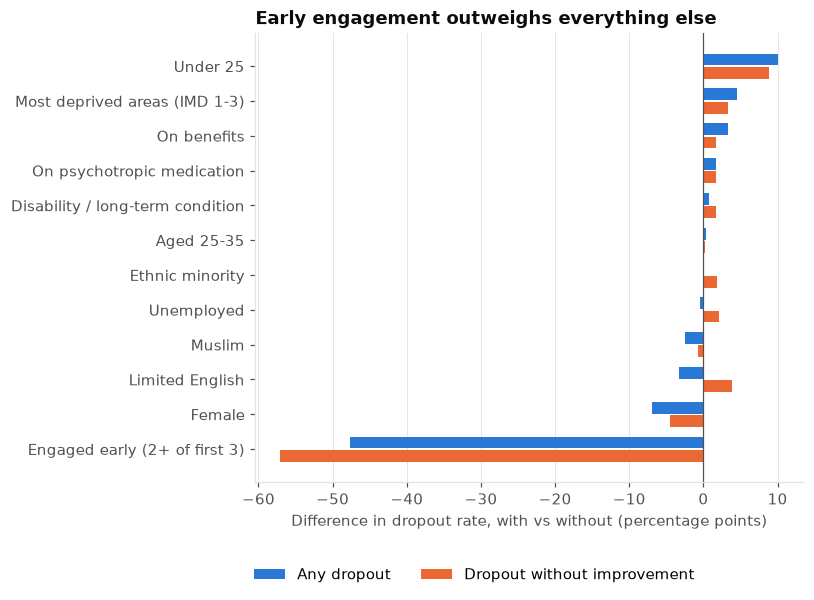

In [6]:
piv = by_factor.pivot(index="factor", columns="target", values="difference (pts)")
piv = piv.loc[piv["Any dropout"].sort_values().index]
y = np.arange(len(piv))
h = 0.38

fig, ax = plt.subplots(figsize=(7.5, 5.6))
ax.barh(y + h / 2, piv["Any dropout"], height=h - 0.04, color=BLUE, label="Any dropout")
ax.barh(y - h / 2, piv["Without improvement"], height=h - 0.04, color=ORANGE, label="Dropout without improvement")
ax.axvline(0, color=MUTED, linewidth=0.8)
ax.set_yticks(y, piv.index)
ax.set_xlabel("Difference in dropout rate, with vs without (percentage points)")
ax.set_title("Early engagement outweighs everything else")
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.4, -0.16), ncol=2)
plt.tight_layout()
plt.show()

Dropout by how many of the first three sessions were attended:

In [7]:
(df.groupby("early_sessions_attended")[["is_dropped_out", "left_unimproved"]]
   .agg(["mean", "size"]).round(3))

is_dropped_out       left_unimproved      
                                  mean  size            mean  size
early_sessions_attended                                           
1                                0.838   241           0.776   241
2                                0.494   946           0.367   946
3                                0.316  2793           0.151  2793

## Preparing the features

Everything here is known by the end of session 3. A few choices:

- `early_phq9_change` is missing when fewer than two of the first three
  sessions were attended, since there's nothing to compare. I fill it with 0
  (no observed change). `early_sessions_attended` already tells the model
  which patients these are.
- Ethnicity is a single flag, ethnic minority vs White. Kanso et al. name
  ethnicity as a key predictor but don't single out particular groups, and
  splitting it into small groups only adds noise (see the large-sample
  section). For religion I include being Muslim, the category the paper
  selected. Limited English is included as the paper's strongest cultural
  predictor.
- `is_early_engaged` is left out because it's just a cut of
  `early_sessions_attended`.

In [8]:
numeric = ["baseline_phq9", "baseline_gad7", "imd_decile", "early_sessions_attended", "early_phq9_change"]
binary = ["is_under_25", "is_25_to_35", "is_female", "is_ethnic_minority", "is_unemployed", "is_on_benefits",
          "has_disability_ltc", "on_psychotropic_med", "has_limited_english", "is_muslim"]

X = df[numeric + binary].copy()
X["early_phq9_change"] = X["early_phq9_change"].fillna(0)
X = X.astype(float)

targets = {"Any dropout": df["is_dropped_out"].astype(int),
           "Dropout without improvement": df["left_unimproved"].astype(int)}
X.describe().T[["mean", "min", "max"]]

,mean,min,max
baseline_phq9,14.947,0.0,27.0
baseline_gad7,11.994,0.0,21.0
imd_decile,4.701,1.0,10.0
early_sessions_attended,2.641,1.0,3.0
early_phq9_change,-1.008,-9.0,6.0
is_under_25,0.222,0.0,1.0
is_25_to_35,0.330,0.0,1.0
is_female,0.736,0.0,1.0
is_ethnic_minority,0.436,0.0,1.0
is_unemployed,0.237,0.0,1.0


## Logistic regression: what's associated with dropout

Fitted on the full dataset to get odds ratios with confidence intervals.
An odds ratio above 1 means higher odds of dropout. These are associations,
not causes. For example, being on benefits doesn't make someone drop out,
but it may stand in for things like money, time or caring
responsibilities that make attending harder.

In [9]:
labels = {
    "baseline_phq9": "Baseline PHQ-9 (per point)",
    "baseline_gad7": "Baseline GAD-7 (per point)",
    "early_sessions_attended": "Early sessions attended (per session)",
    "early_phq9_change": "Early PHQ-9 change (per point)",
    "imd_decile": "IMD decile (per decile less deprived)",
    "is_under_25": "Under 25 (vs 36+)", "is_25_to_35": "Aged 25-35 (vs 36+)", "is_female": "Female",
    "is_unemployed": "Unemployed", "is_on_benefits": "On benefits",
    "has_disability_ltc": "Disability / LTC", "on_psychotropic_med": "Psychotropic medication",
    "has_limited_english": "Limited English", "is_muslim": "Muslim",
    "is_ethnic_minority": "Ethnic minority (vs White)",
}

def odds_ratios(y):
    fit = sm.Logit(y, sm.add_constant(X)).fit(disp=0)
    ci = np.exp(fit.conf_int())
    return pd.DataFrame({"OR": np.exp(fit.params), "low": ci[0], "high": ci[1],
                         "p": fit.pvalues}).drop("const")

ors = {name: odds_ratios(y) for name, y in targets.items()}
table = pd.concat(ors, axis=1).rename(index=labels)
table.round(3)

Any dropout                       \
                                               OR    low   high      p   
Baseline PHQ-9 (per point)                  0.996  0.982  1.010  0.566   
Baseline GAD-7 (per point)                  0.998  0.981  1.014  0.780   
IMD decile (per decile less deprived)       0.958  0.934  0.982  0.001   
Early sessions attended (per session)       0.381  0.339  0.428  0.000   
Early PHQ-9 change (per point)              0.978  0.939  1.018  0.278   
Under 25 (vs 36+)                           1.597  1.345  1.896  0.000   
Aged 25-35 (vs 36+)                         1.206  1.034  1.407  0.017   
Female                                      0.732  0.631  0.851  0.000   
Ethnic minority (vs White)                  1.034  0.897  1.192  0.640   
Unemployed                                  0.954  0.813  1.119  0.562   
On benefits                                 1.096  0.927  1.295  0.284   
Disability / LTC                            1.059  0.895  1.253  0.502   
Psychotropic medication                     1.093  0.946  1.263  0.227   
Limited English                             0.840  0.608  1.159  0.289   
Muslim                                      0.888  0.703  1.120  0.316   

                                      Dropout without improvement         \
                                                               OR    low   
Baseline PHQ-9 (per point)                                  0.995  0.979   
Baseline GAD-7 (per point)                                  0.925  0.906   
IMD decile (per decile less deprived)                       0.968  0.939   
Early sessions attended (per session)                       0.264  0.233   
Early PHQ-9 change (per point)                              1.134  1.078   
Under 25 (vs 36+)                                           1.709  1.397   
Aged 25-35 (vs 36+)                                         1.260  1.045   
Female                                                      0.756  0.633   
Ethnic minority (vs White)                                  1.152  0.972   
Unemployed                                                  1.116  0.924   
On benefits                                                 1.010  0.827   
Disability / LTC                                            1.152  0.944   
Psychotropic medication                                     1.111  0.936   
Limited English                                             1.106  0.768   
Muslim                                                      0.851  0.643   

                                                     
                                        high      p  
Baseline PHQ-9 (per point)             1.011  0.512  
Baseline GAD-7 (per point)             0.944  0.000  
IMD decile (per decile less deprived)  0.997  0.031  
Early sessions attended (per session)  0.300  0.000  
Early PHQ-9 change (per point)         1.193  0.000  
Under 25 (vs 36+)                      2.091  0.000  
Aged 25-35 (vs 36+)                    1.519  0.016  
Female                                 0.902  0.002  
Ethnic minority (vs White)             1.365  0.103  
Unemployed                             1.347  0.255  
On benefits                            1.234  0.919  
Disability / LTC                       1.405  0.163  
Psychotropic medication                1.320  0.229  
Limited English                        1.593  0.589  
Muslim                                 1.126  0.258

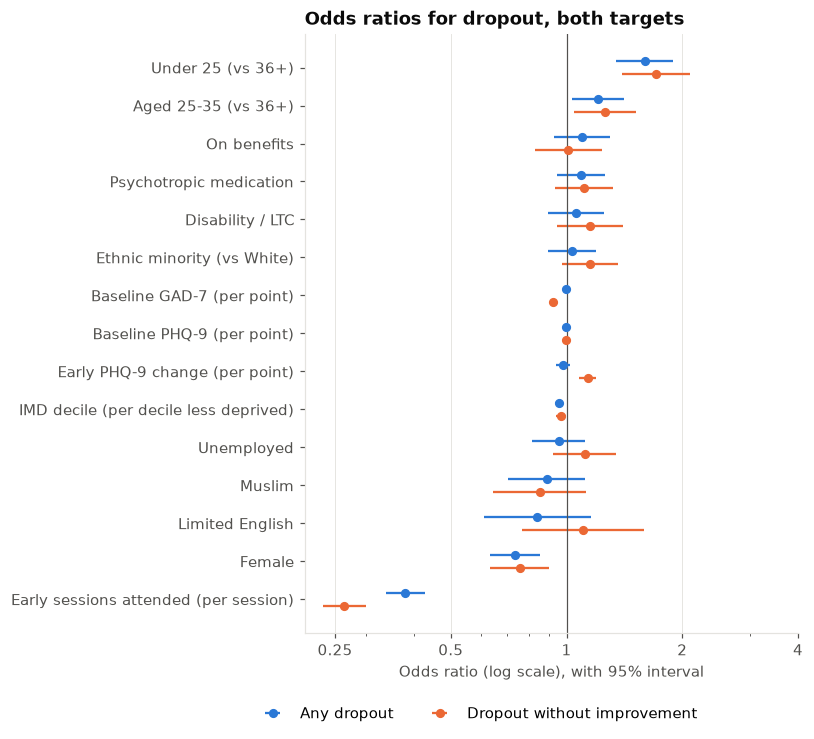

In [10]:
order = ors["Any dropout"]["OR"].sort_values().index
y = np.arange(len(order))
fig, ax = plt.subplots(figsize=(7.5, 6.8))
for (name, res), color, off in zip(ors.items(), [BLUE, ORANGE], [0.17, -0.17]):
    r = res.loc[order]
    ax.errorbar(r["OR"], y + off, xerr=[r["OR"] - r["low"], r["high"] - r["OR"]],
                fmt="o", color=color, markersize=5, elinewidth=1.5, capsize=0, label=name)
ax.axvline(1, color=MUTED, linewidth=0.8)
ax.set_xscale("log")
ax.set_xticks([0.25, 0.5, 1, 2, 4], ["0.25", "0.5", "1", "2", "4"])
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_yticks(y, [labels[c] for c in order])
ax.set_xlabel("Odds ratio (log scale), with 95% interval")
ax.set_title("Odds ratios for dropout, both targets")
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.35, -0.1), ncol=2)
plt.tight_layout()
plt.show()

## How well can dropout be predicted?

Now a held-out test: train on 75% of patients, score on the other 25%.
Three models are compared. Plain logistic regression. Elastic net logistic
regression, tuned by 5-fold cross-validation over the same grid as Kanso et
al., to match their method. And a gradient-boosted tree model, which can pick
up interactions and non-linear effects the regressions can't. Performance
is measured with AUC (0.5 is a coin toss, 1.0 is perfect).

In [11]:
models = {
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Elastic net (as Kanso et al.)": make_pipeline(StandardScaler(), LogisticRegressionCV(
        solver="saga", l1_ratios=[0.1, 0.3, 0.5, 0.7, 0.9],
        Cs=[0.01, 0.1, 1.0, 10.0], cv=5, scoring="roc_auc", max_iter=5000, random_state=42)),
    "Gradient boosting": HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05,
                                                        max_iter=300, random_state=42),
}
results, curves, test_preds = [], {}, {}
for tname, y in targets.items():
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
    for mname, model in models.items():
        p = model.fit(X_tr, y_tr).predict_proba(X_te)[:, 1]
        results.append({"target": tname, "model": mname, "test AUC": roc_auc_score(y_te, p)})
        curves[(tname, mname)] = roc_curve(y_te, p)
        test_preds[(tname, mname)] = pd.DataFrame({"y": y_te, "p": p}, index=y_te.index)
pd.DataFrame(results).pivot(index="model", columns="target", values="test AUC").round(3)

target,Any dropout,Dropout without improvement
model,,
Elastic net (as Kanso et al.),0.652,0.721
Gradient boosting,0.686,0.743
Logistic regression,0.662,0.724


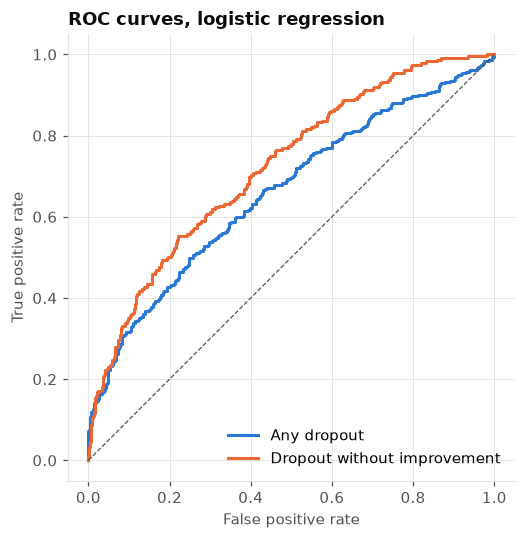

In [12]:
fig, ax = plt.subplots(figsize=(5.5, 5))
for tname, color in [("Any dropout", BLUE), ("Dropout without improvement", ORANGE)]:
    fpr, tpr, _ = curves[(tname, "Logistic regression")]
    ax.plot(fpr, tpr, color=color, linewidth=2, label=tname)
ax.plot([0, 1], [0, 1], color=MUTED, linewidth=0.8, linestyle="--")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("ROC curves, logistic regression")
ax.set_aspect("equal")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

## Does the model work equally well for everyone?

If a service used a model like this to decide who gets extra support, it
should be about as accurate for every group. Some groups are small, so
rather than the 25% test set I use 5-fold cross-validated predictions for
all patients, each one made by a model that never saw that patient. Using
the logistic regression:

- **AUC within each group**: how well it ranks patients from the same group.
- **Predicted vs actual dropout rate**: whether it over- or under-estimates
  risk for a group. A model can rank well and still be off on the overall level.

In [13]:
rows = []
for tname in targets:
    y = targets[tname]
    p = cross_val_predict(models["Logistic regression"], X, y, method="predict_proba",
                          cv=StratifiedKFold(5, shuffle=True, random_state=42))[:, 1]
    t = pd.DataFrame({"y": y, "p": p}).join(
        df[["is_ethnic_minority", "is_muslim", "has_limited_english", "is_most_deprived"]])
    groups = [("Ethnic minority", t["is_ethnic_minority"]), ("White", ~t["is_ethnic_minority"]),
              ("Muslim", t["is_muslim"]), ("Not Muslim", ~t["is_muslim"]),
              ("Limited English", t["has_limited_english"]), ("Fluent English", ~t["has_limited_english"]),
              ("Most deprived (IMD 1-3)", t["is_most_deprived"]), ("Less deprived (IMD 4-10)", ~t["is_most_deprived"])]
    for g, mask in groups:
        sub = t[mask]
        rows.append({"target": tname, "group": g, "n": len(sub),
                     "AUC": roc_auc_score(sub["y"], sub["p"]) if sub["y"].nunique() == 2 else np.nan,
                     "actual rate": sub["y"].mean(), "predicted rate": sub["p"].mean()})
fairness = pd.DataFrame(rows)
fairness.pivot(index="group", columns="target", values=["n", "AUC", "actual rate", "predicted rate"]).round(3)

n                                     AUC  \
target                   Any dropout Dropout without improvement Any dropout   
group                                                                          
Ethnic minority               1736.0                      1736.0       0.650   
Fluent English                3785.0                      3785.0       0.648   
Less deprived (IMD 4-10)      2407.0                      2407.0       0.634   
Limited English                195.0                       195.0       0.671   
Most deprived (IMD 1-3)       1573.0                      1573.0       0.666   
Muslim                         403.0                       403.0       0.658   
Not Muslim                    3577.0                      3577.0       0.647   
White                         2244.0                      2244.0       0.649   

                                                     actual rate  \
target                   Dropout without improvement Any dropout   
group                                                              
Ethnic minority                                0.735       0.389   
Fluent English                                 0.745       0.392   
Less deprived (IMD 4-10)                       0.734       0.372   
Limited English                                0.755       0.359   
Most deprived (IMD 1-3)                        0.760       0.418   
Muslim                                         0.770       0.367   
Not Muslim                                     0.743       0.393   
White                                          0.752       0.390   

                                                     predicted rate  \
target                   Dropout without improvement    Any dropout   
group                                                                 
Ethnic minority                                0.251          0.389   
Fluent English                                 0.238          0.391   
Less deprived (IMD 4-10)                       0.227          0.371   
Limited English                                0.277          0.359   
Most deprived (IMD 1-3)                        0.260          0.419   
Muslim                                         0.233          0.366   
Not Muslim                                     0.241          0.392   
White                                          0.232          0.390   

                                                      
target                   Dropout without improvement  
group                                                 
Ethnic minority                                0.251  
Fluent English                                 0.238  
Less deprived (IMD 4-10)                       0.226  
Limited English                                0.277  
Most deprived (IMD 1-3)                        0.261  
Muslim                                         0.232  
Not Muslim                                     0.241  
White                                          0.231

## What a bigger sample shows

With about 4,000 patients, small effects are hard to pin down. Most of the
paper's social and cultural predictors come out non-significant above, and a
couple point the "wrong" way: being Muslim and limited English both show odds
below 1 for dropout, despite making outcomes worse in this data.

Because the data is generated, I can check this directly. Below, the
generator makes 60,000 patients with exactly the same settings, the same
features are built (in Python here, mirroring the dbt models), and the same
logistic regression is fitted. With 12 times the data, the estimates settle
close to their true values.

In [14]:
import sys
sys.path.insert(0, "../generator")
from generate_data import generate

big_p, big_s = generate(60000, seed=7)
big = big_p[~big_p["referral_terminated"]].set_index("patient_id")

early = big_s[big_s["session_number"] <= 3]
scores = early[early["attended"]].sort_values("session_number").groupby("patient_id")["phq9_score"]
big["early_sessions_attended"] = early.groupby("patient_id")["attended"].sum()
big["early_phq9_change"] = (scores.last() - scores.first()).where(scores.size() >= 2)

Xb = pd.DataFrame({
    "baseline_phq9": big["baseline_phq9"], "baseline_gad7": big["baseline_gad7"],
    "imd_decile": big["imd_decile"], "early_sessions_attended": big["early_sessions_attended"],
    "early_phq9_change": big["early_phq9_change"].fillna(0),
    "is_under_25": big["age"] < 25, "is_25_to_35": big["age"].between(25, 35),
    "is_female": big["female"], "is_unemployed": big["unemployed"],
    "is_on_benefits": big["on_benefits"], "has_disability_ltc": big["disability_ltc"],
    "on_psychotropic_med": big["psychotropic_med"],
    "has_limited_english": big["limited_english"], "is_muslim": big["religion"] == "Muslim",
    "is_ethnic_minority": big["ethnicity"] != "White",
}).astype(float)[X.columns]

big_targets = {"Any dropout": big["dropped_out"].astype(int),
               "Dropout without improvement": (big["dropped_out"] & ~big["reliable_improvement"]).astype(int)}

def fit_ors(Xm, y):
    fit = sm.Logit(y, sm.add_constant(Xm)).fit(disp=0)
    ci = np.exp(fit.conf_int())
    return pd.DataFrame({"OR": np.exp(fit.params), "low": ci[0], "high": ci[1]}).drop("const")

big_ors = {name: fit_ors(Xb, y) for name, y in big_targets.items()}
print(f"{len(big):,} patients who started treatment")

48,033 patients who started treatment


In [15]:
focus = ["early_sessions_attended", "early_phq9_change", "is_under_25", "is_25_to_35",
         "is_female", "imd_decile", "is_unemployed", "is_on_benefits", "has_disability_ltc",
         "on_psychotropic_med", "has_limited_english", "is_muslim", "is_ethnic_minority",
         "baseline_phq9", "baseline_gad7"]
fmt = lambda r: f"{r.OR:.2f} ({r.low:.2f}-{r.high:.2f})"
compare = pd.DataFrame({
    (t, size): [fmt(res.loc[c]) for c in focus]
    for t in targets
    for size, res in [("~4,000 patients", ors[t]), ("~48,000 patients", big_ors[t])]
}, index=[labels[c] for c in focus])
compare

Any dropout                    \
                                        ~4,000 patients  ~48,000 patients   
Early sessions attended (per session)  0.38 (0.34-0.43)  0.41 (0.39-0.42)   
Early PHQ-9 change (per point)         0.98 (0.94-1.02)  0.99 (0.98-1.00)   
Under 25 (vs 36+)                      1.60 (1.34-1.90)  1.50 (1.42-1.57)   
Aged 25-35 (vs 36+)                    1.21 (1.03-1.41)  1.18 (1.13-1.24)   
Female                                 0.73 (0.63-0.85)  0.90 (0.86-0.93)   
IMD decile (per decile less deprived)  0.96 (0.93-0.98)  0.94 (0.93-0.95)   
Unemployed                             0.95 (0.81-1.12)  1.00 (0.96-1.05)   
On benefits                            1.10 (0.93-1.29)  1.00 (0.95-1.05)   
Disability / LTC                       1.06 (0.90-1.25)  1.02 (0.97-1.07)   
Psychotropic medication                1.09 (0.95-1.26)  0.95 (0.91-0.99)   
Limited English                        0.84 (0.61-1.16)  0.99 (0.90-1.09)   
Muslim                                 0.89 (0.70-1.12)  1.02 (0.95-1.08)   
Ethnic minority (vs White)             1.03 (0.90-1.19)  1.11 (1.06-1.15)   
Baseline PHQ-9 (per point)             1.00 (0.98-1.01)  0.99 (0.99-1.00)   
Baseline GAD-7 (per point)             1.00 (0.98-1.01)  0.99 (0.98-0.99)   

                                      Dropout without improvement  \
                                                  ~4,000 patients   
Early sessions attended (per session)            0.26 (0.23-0.30)   
Early PHQ-9 change (per point)                   1.13 (1.08-1.19)   
Under 25 (vs 36+)                                1.71 (1.40-2.09)   
Aged 25-35 (vs 36+)                              1.26 (1.04-1.52)   
Female                                           0.76 (0.63-0.90)   
IMD decile (per decile less deprived)            0.97 (0.94-1.00)   
Unemployed                                       1.12 (0.92-1.35)   
On benefits                                      1.01 (0.83-1.23)   
Disability / LTC                                 1.15 (0.94-1.41)   
Psychotropic medication                          1.11 (0.94-1.32)   
Limited English                                  1.11 (0.77-1.59)   
Muslim                                           0.85 (0.64-1.13)   
Ethnic minority (vs White)                       1.15 (0.97-1.36)   
Baseline PHQ-9 (per point)                       0.99 (0.98-1.01)   
Baseline GAD-7 (per point)                       0.92 (0.91-0.94)   

                                                         
                                       ~48,000 patients  
Early sessions attended (per session)  0.28 (0.27-0.29)  
Early PHQ-9 change (per point)         1.17 (1.15-1.18)  
Under 25 (vs 36+)                      1.62 (1.52-1.71)  
Aged 25-35 (vs 36+)                    1.21 (1.15-1.28)  
Female                                 0.87 (0.83-0.92)  
IMD decile (per decile less deprived)  0.93 (0.92-0.93)  
Unemployed                             1.14 (1.08-1.21)  
On benefits                            1.08 (1.02-1.14)  
Disability / LTC                       1.10 (1.04-1.17)  
Psychotropic medication                1.03 (0.98-1.08)  
Limited English                        1.08 (0.97-1.21)  
Muslim                                 1.03 (0.95-1.11)  
Ethnic minority (vs White)             1.15 (1.09-1.21)  
Baseline PHQ-9 (per point)             1.01 (1.00-1.01)  
Baseline GAD-7 (per point)             0.92 (0.92-0.93)

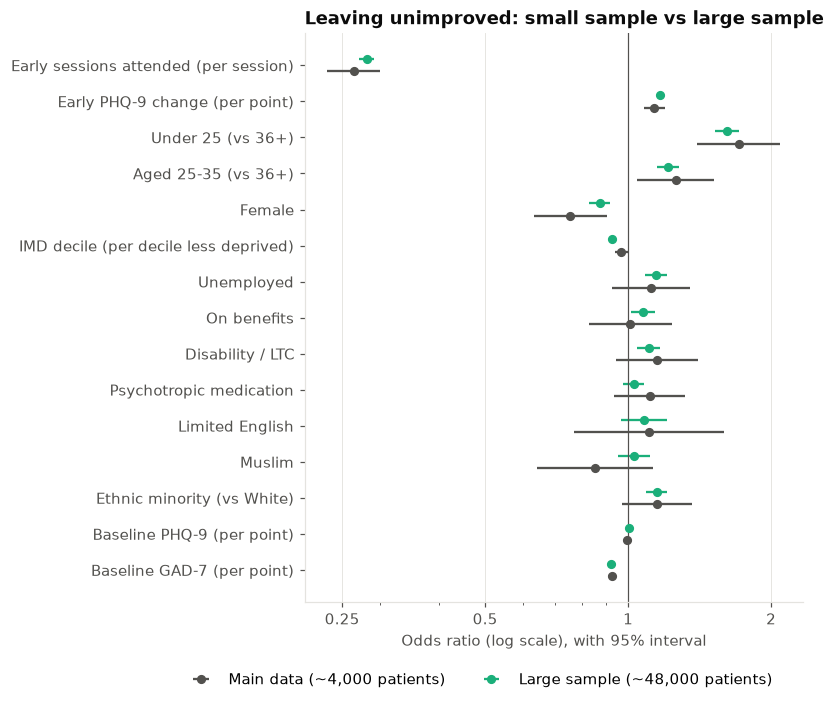

In [16]:
t = "Dropout without improvement"
y = np.arange(len(focus))
fig, ax = plt.subplots(figsize=(7.5, 6.5))
for res, color, off, name in [(ors[t], MUTED, 0.17, "Main data (~4,000 patients)"),
                              (big_ors[t], "#1baf7a", -0.17, "Large sample (~48,000 patients)")]:
    r = res.loc[focus]
    ax.errorbar(r["OR"], y + off, xerr=[r["OR"] - r["low"], r["high"] - r["OR"]],
                fmt="o", color=color, markersize=5, elinewidth=1.5, capsize=0, label=name)
ax.axvline(1, color=MUTED, linewidth=0.8)
ax.set_xscale("log")
ax.set_xticks([0.25, 0.5, 1, 2], ["0.25", "0.5", "1", "2"])
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_yticks(y, [labels[c] for c in focus])
ax.invert_yaxis()
ax.set_xlabel("Odds ratio (log scale), with 95% interval")
ax.set_title("Leaving unimproved: small sample vs large sample")
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.35, -0.1), ncol=2)
plt.tight_layout()
plt.show()

With the larger sample, the picture is much more consistent:

- **The paper's social factors show up for leaving unimproved, but not for
  dropout as a whole.** Unemployment (1.14), benefits (1.08) and disability
  or long-term condition (1.10) all raise the odds of leaving unimproved,
  but sit at about 1.0 for any dropout. That's the two kinds of leaver
  cancelling out. Psychotropic medication even dips below 1 for any dropout
  (0.95), because people on it are less likely to leave feeling better.
- **Ethnicity has a small, real effect on both:** 1.11 for any dropout and
  1.15 for leaving unimproved. The main data gets 1.15 for leaving unimproved
  too, but with an interval of 0.97 to 1.36, so it can't call it.
- **Limited English (1.08) and being Muslim (1.03) are too small to detect
  even with 48,000 patients.** They only affect dropout through outcomes, and
  that link is weak. Their values below 1 in the main data were noise.
- **Even the clearer effects move.** Age holds up well. But the main data
  overstates the sex effect (women 0.73 vs 0.90 for any dropout) and
  understates deprivation (0.96 vs 0.94 per decile).

So the main data gets the direction of the bigger effects right, but its
sizes are only approximate, and it can't be trusted on effects this small.
That's why studies like Kanso et al. and Burke et al. need tens of thousands
of patients.

## What this shows

The generator's effects come from two sources. Effects on **outcomes**
follow Kanso et al. (2026). Direct effects on **dropout** follow Burke et
al. (2025), plus a small ethnicity effect of my own (see the README). So the
real question here isn't whether the model finds effects. It's what it can
and can't pick up, and what that means for real data.

**Early attendance is by far the strongest signal.** Each extra session
attended out of the first three cuts the odds of dropping out by about 60%
(odds ratio 0.38), and the odds of leaving unimproved by about 75% (0.26).
Of the patients who came to only one of their first three sessions, 84% went
on to drop out. Some of them had already stopped coming by session 3, so part
of this is spotting dropout that's already under way.

**Age, sex and deprivation come through clearly.** Under-25s have about
1.6 times the odds of dropping out compared with over-35s, and 25-35s about
1.2 times. Women have lower odds than men (0.73, although the large sample
shows the true effect is smaller, about 0.90). Each step towards a less
deprived area lowers the odds by about 4 to 6%. These match Burke et al. in
direction, which is what they were built to do.

**The paper's social and cultural predictors matter for leaving unimproved,
not for dropout as a whole.** Unemployment, benefits, disability, limited
English, being Muslim and ethnicity all make recovery less likely in this
data. In the main data none of them is significant for dropout. The large
sample shows why. Unemployment (1.14), benefits (1.08), disability (1.10)
and ethnicity (1.15) do raise the odds of leaving unimproved, but for
dropout as a whole their effect is cancelled out: people who are doing worse
are less likely to leave because they feel better. Limited English and being
Muslim affect dropout so little that even 48,000 patients can't detect it.

**Ethnicity has a small direct effect, and this sample is too small to
measure it.** In the large sample, ethnic minority patients have about 1.1
times the odds of dropping out. In the main data the estimate is 1.03 for
any dropout and 1.15 for leaving unimproved, with intervals that include no
effect. That's also why Burke et al.'s null result for ethnicity, which
compared White British patients with everyone else in a mostly White British
area, isn't strong evidence that there's no effect.

**The two targets still differ.** Early symptom change matters only for
leaving unimproved: each point less improvement in PHQ-9 over the first
three sessions raises the odds by 13%. Baseline GAD-7 also only matters
there, but that's a measurement effect. Reliable improvement needs a fixed
drop of 4 points, which is easier from a high starting score.

**Prediction is moderate.** Test AUC is 0.65 to 0.69 for any dropout and
0.72 to 0.74 for leaving unimproved. Gradient boosting does best by about
0.03. The elastic net doesn't improve on plain logistic regression. With
this few predictors, there's little for regularisation to do.

**The model works about equally well across groups.** Comparing ethnic
minority and White patients, Muslim and non-Muslim, limited and fluent
English, and more and less deprived areas, AUC within each group is 0.63 to
0.67 for any dropout and 0.73 to 0.77 for leaving unimproved. Predicted
dropout rates match actual ones within a point. That's expected,
because the synthetic data has no group-specific patterns the model can't
see. On real NHS Talking Therapies data, Shipman and Ushakova (2026) found
large gaps across age and ethnic groups, so this check matters more there
than it does here.

### Limitations

- The data is synthetic. Every effect exists because I put it there, sized
  from published estimates where they exist and by judgement where they
  don't (the ethnicity effect on dropout, and the two kinds of leaver).
- One train/test split for the AUCs, which would move a few points with a
  different split.
- "Dropout without improvement" uses the final score, which a service
  wouldn't have at session 3. That's fine for deciding who to study, but
  this target couldn't be scored in real time as it is.
- In the generator, severely affected patients show less reliable
  improvement than moderate ones. Real data usually shows the opposite,
  because higher starting scores leave more room to fall.

### Sources

- Kanso et al. (2026). Building a prediction model for outcomes following
  treatment in UK NHS Talking Therapies. medRxiv.
  https://www.medrxiv.org/content/10.64898/2026.03.12.26348223v2
- Burke et al. (2025). Recovery, completion and further referral after
  Improving Access to Psychological Therapies in Norfolk and Waveney.
  BJPsych Open. https://doi.org/10.1192/bjo.2025.10045
- Harwood et al. (2023). Variations by ethnicity in referral and treatment
  pathways for IAPT service users in South London. Psychological Medicine.
- Swift & Greenberg (2012). Premature discontinuation in adult
  psychotherapy: a meta-analysis. Journal of Consulting and Clinical
  Psychology.
- Shipman & Ushakova (2026). Fairness-aware machine learning for predicting
  recovery and dropout in NHS Talking Therapies. BJPsych Open.